## ⾝份与环境记录

In [14]:
import hashlib
import os
import platform
import uuid

STUDENT_ID = 20244630202
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp_env
[学号] 20244630202
[机器指纹] b5fff4197e9c8b2c
[RUN_ID] 20244630202-b5fff4197e9c8b2c


## 一、围绕半圆定律

### 1.编写半圆密度函数 wigner_density(x)

In [15]:
import numpy as np

def wigner_density(x):
    x = float(x)
    if abs(x) > 2:
        return 0.0

    return float(np.sqrt(4 - x ** 2) / (2 * np.pi))
# 测试不同位置的密度值
test_points = [-3, -2, -1.5, 0, 1.5, 2, 3.11]
for x in test_points:
    value = wigner_density(x)
    print(f"x = {x:>2}, f(x) = {value:.6f}, 返回类型 = {type(value).__name__}")

x = -3, f(x) = 0.000000, 返回类型 = float
x = -2, f(x) = 0.000000, 返回类型 = float
x = -1.5, f(x) = 0.210542, 返回类型 = float
x =  0, f(x) = 0.318310, 返回类型 = float
x = 1.5, f(x) = 0.210542, 返回类型 = float
x =  2, f(x) = 0.000000, 返回类型 = float
x = 3.11, f(x) = 0.000000, 返回类型 = float


### 2.编写 Wigner 矩阵生成函数

In [16]:
def generate_wigner(n):
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是正整数")
    if n <= 0:
        raise ValueError("n 必须大于 0")
    random_matrix = np.random.normal(
        loc=0.0,
        scale=np.sqrt(1 / n),
        size=(n, n)
    )
    upper = np.triu(random_matrix)
    wigner_matrix = upper + upper.T - np.diag(np.diag(upper))

    return wigner_matrix

# 测试矩阵生成
np.random.seed(42)
Z = generate_wigner(5)

print("生成的 5×5 Wigner 矩阵：")
print(Z)
print("\n矩阵形状：", Z.shape)
print("是否为对称矩阵：", np.allclose(Z, Z.T))
# 测试非法输入
for invalid_n in [0, -3, 2.5, "5", True]:
    try:
        generate_wigner(invalid_n)
    except (TypeError, ValueError) as error:
        print(f"输入 {invalid_n!r}：{type(error).__name__} - {error}")


生成的 5×5 Wigner 矩阵：
[[ 0.22213732 -0.06183368  0.28965512  0.68111966 -0.10471657]
 [-0.06183368  0.70624544  0.34320724 -0.20995533  0.24264023]
 [ 0.28965512  0.34320724  0.10820882 -0.85564494 -0.77140671]
 [ 0.68111966 -0.20995533 -0.85564494 -0.40608071 -0.63160142]
 [-0.10471657  0.24264023 -0.77140671 -0.63160142 -0.24345536]]

矩阵形状： (5, 5)
是否为对称矩阵： True
输入 0：ValueError - n 必须大于 0
输入 -3：ValueError - n 必须大于 0
输入 2.5：TypeError - n 必须是正整数
输入 '5'：TypeError - n 必须是正整数
输入 True：TypeError - n 必须是正整数


### 3. 编写特征值计算函数 get_spectrum(matrix)

In [17]:
def get_spectrum(matrix):
    """计算实对称矩阵的全部特征值，结果按非递减顺序排列。"""
    return np.linalg.eigvalsh(matrix)

# 使用上一个子任务生成的矩阵进行测试
eigenvalues = get_spectrum(Z)

print("矩阵的全部特征值：")
print(eigenvalues)
print("\n返回类型：", type(eigenvalues))
print("是否按非递减顺序排列：", np.all(np.diff(eigenvalues) >= 0))
print("特征值数量：", len(eigenvalues))


矩阵的全部特征值：
[-1.85298615 -0.23934891  0.44782011  0.86097165  1.17059882]

返回类型： <class 'numpy.ndarray'>
是否按非递减顺序排列： True
特征值数量： 5


### 4.绘制不同矩阵阶数下的特征值分布

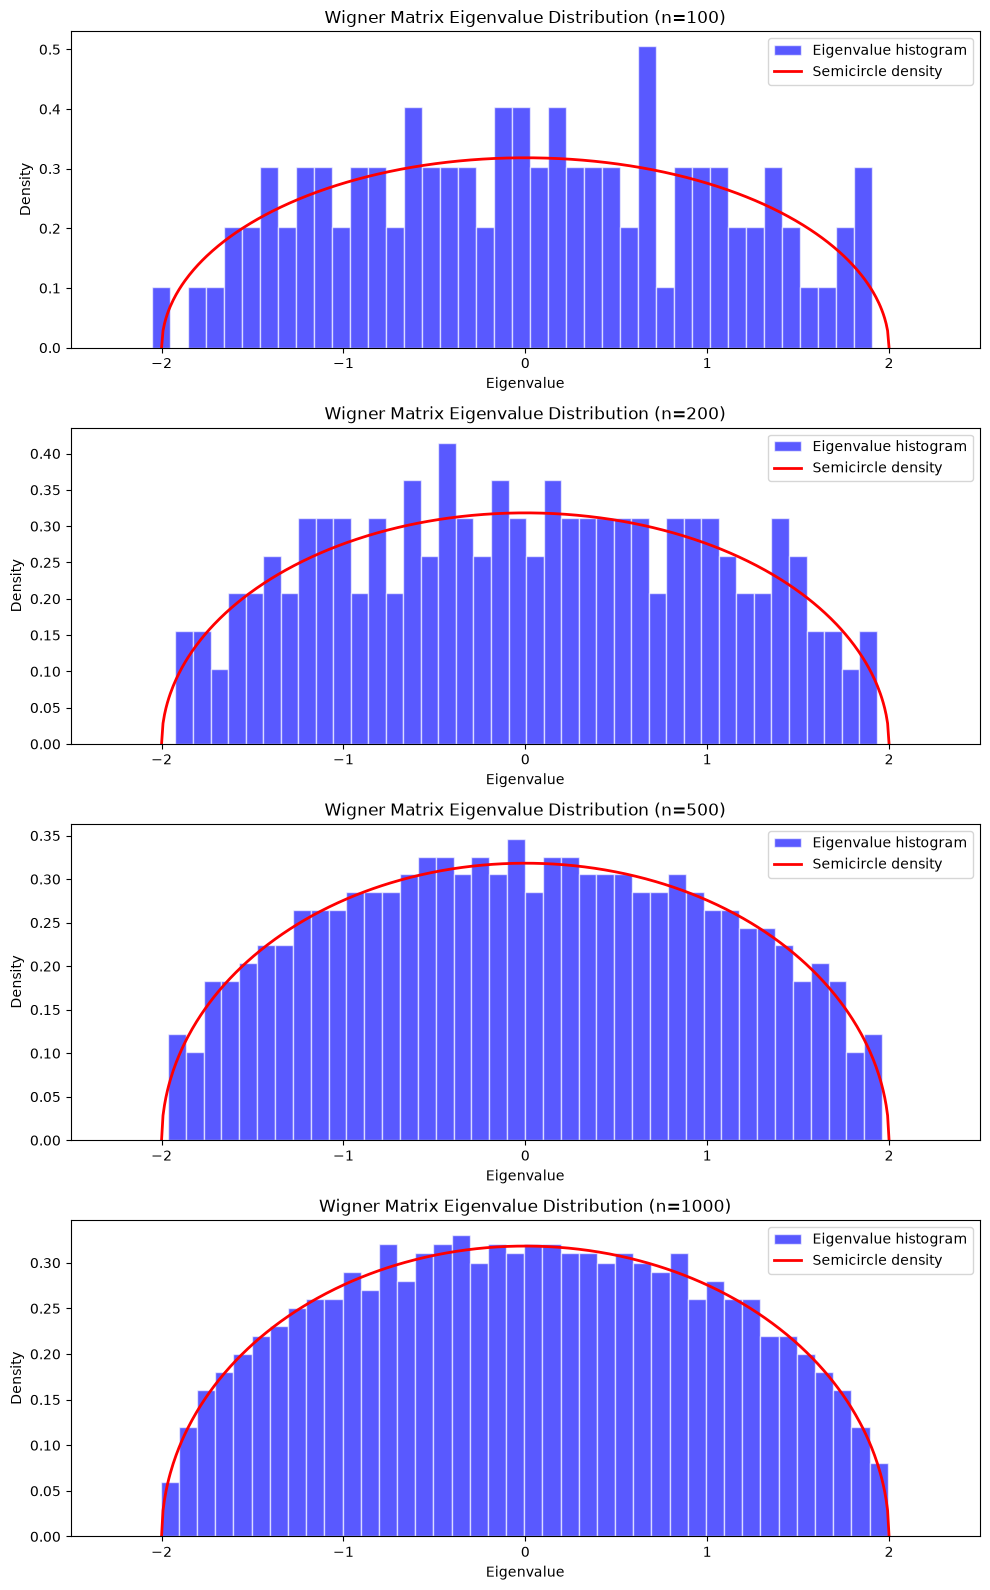

In [18]:
import matplotlib.pyplot as plt

np.random.seed(42)

n_values = [100, 200, 500, 1000]
x_curve = np.linspace(-2, 2, 500)
density_curve = np.array([wigner_density(x) for x in x_curve])

fig, axes = plt.subplots(4, 1, figsize=(10, 16))

for ax, n in zip(axes, n_values):
    matrix = generate_wigner(n)
    eigenvalues = get_spectrum(matrix)

    ax.hist(
        eigenvalues,
        bins=40,
        density=True,
        color="blue",
        alpha=0.65,
        edgecolor="white",
        label="Eigenvalue histogram"
    )

    ax.plot(
        x_curve,
        density_curve,
        color="red",
        linewidth=2,
        label="Semicircle density"
    )

    ax.set_title(f"Wigner Matrix Eigenvalue Distribution (n={n})")
    ax.set_xlabel("Eigenvalue")
    ax.set_ylabel("Density")
    ax.set_xlim(-2.5, 2.5)
    ax.legend()

plt.tight_layout()
plt.show()

### 分布拟合分析

根据上述四个子图的对比结果：
* **当 $n = 100$ 或 $200$ 时**：特征值标准化直方图的局部起伏和尖峰较明显，与红色半圆密度曲线存在一定偏差。
* **当 $n \approx 500$ 时**：直方图整体轮廓已能较好地贴合半圆密度曲线，边缘与中心区域的分布趋势趋于一致。
* **当 $n = 1000$ 时**：直方图更加平滑，与半圆密度的拟合度进一步提高，直观体现了 Wigner 半圆定律随矩阵阶数 $n$ 增大的收敛性。

**结论**：$n$ 大约达到 **500** 左右时，半圆密度就已经能较好地拟合特征值分布；在 $n = 1000$ 时拟合效果更稳定。

## 二、Conway 的生命游戏

### 1.编写棋盘合法性检查函数

In [19]:
def is_valid_board(board):
    """判断输入是否为元素只包含整数 0、1 的非空二维 NumPy 数组。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2 or board.size == 0:
        return False
    if board.dtype.kind not in ("i", "u"):
        return False
    return bool(np.isin(board, [0, 1]).all())


# 合法棋盘测试
valid_board = np.array([
    [0, 1, 0],
    [1, 1, 0],
    [0, 0, 1]
])

print("合法棋盘：")
print(valid_board)
print("检查结果：", is_valid_board(valid_board))

# 非法棋盘测试
invalid_boards = [
    [[0, 1], [1, 0]],                 # 普通 Python 列表
    np.array([0, 1, 0]),              # 一维数组
    np.array([[0, 1], [1, 2]]),       # 含有 2
    np.array([[0, 1], [1, -1]])       # 含有 -1
]

for item in invalid_boards:
    print(f"输入：{item}，检查结果：{is_valid_board(item)}")


合法棋盘：
[[0 1 0]
 [1 1 0]
 [0 0 1]]
检查结果： True
输入：[[0, 1], [1, 0]]，检查结果：False
输入：[0 1 0]，检查结果：False
输入：[[0 1]
 [1 2]]，检查结果：False
输入：[[ 0  1]
 [ 1 -1]]，检查结果：False


### 2.编写生命游戏更新函数 gol_step(board)

In [20]:
def gol_step(board):
    """按照 Conway 生命游戏规则更新一步，使用环绕边界。"""
    if not is_valid_board(board):
        raise ValueError("输入必须是二维 NumPy 数组，且元素只能为 0 或 1")

    original = board.astype(np.uint8, copy=False)
    neighbor_count = np.zeros(original.shape, dtype=int)

    # 累加上、下、左、右及四个对角方向的邻居
    for row_shift in (-1, 0, 1):
        for col_shift in (-1, 0, 1):
            if row_shift == 0 and col_shift == 0:
                continue

            neighbor_count += np.roll(
                original,
                shift=(row_shift, col_shift),
                axis=(0, 1)
            )

    # 活细胞：2或3个活邻居时存活
    # 死细胞：恰好3个活邻居时复活
    next_board = (
        ((original == 1) & ((neighbor_count == 2) | (neighbor_count == 3)))
        | ((original == 0) & (neighbor_count == 3))
    )

    return next_board.astype(np.uint8)

# 用经典的“振荡器”——滑翔机以外的闪烁体（Blinker）测试
gol_board = np.array([
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0]
], dtype=np.uint8)

next_gol_board = gol_step(gol_board)

print("原始棋盘：")
print(gol_board)
print("\n更新一步后的棋盘：")
print(next_gol_board)
print("\n原棋盘是否保持不变：", np.array_equal(
    gol_board,
    np.array([
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 1, 1, 1, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]
    ], dtype=np.uint8)
))
print("新旧棋盘形状是否一致：", gol_board.shape == next_gol_board.shape)

原始棋盘：
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]

更新一步后的棋盘：
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]

原棋盘是否保持不变： True
新旧棋盘形状是否一致： True


### 3.编写棋盘绘图函数 draw_gol_board(board)

原始棋盘：


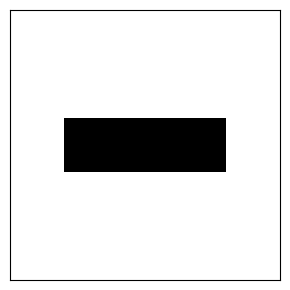

更新一步后的棋盘：


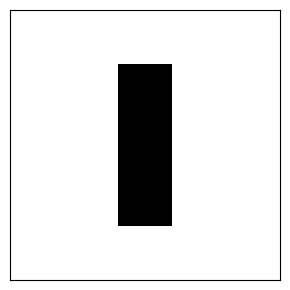

In [21]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def draw_gol_board(board):
    """将有效生命游戏棋盘绘制为黑白方格。"""
    if not is_valid_board(board):
        raise ValueError("输入必须是有效的二维生命游戏棋盘")

    rows, cols = board.shape
    fig, ax = plt.subplots(
        figsize=(max(3, cols * 0.6), max(3, rows * 0.6))
    )

    black_white = ListedColormap(["white", "black"])
    ax.imshow(
        board,
        cmap=black_white,
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")

    plt.tight_layout()
    plt.show()


print("原始棋盘：")
draw_gol_board(gol_board)

print("更新一步后的棋盘：")
draw_gol_board(next_gol_board)

## 三、使⽤ pandas DataFrame

### 1.读取Iris数据集并查看基本信息

In [22]:

import pandas as pd

# 读取老师群里提供的 Iris.csv
iris_df = pd.read_csv("Iris.csv")

# 查看数据集基本信息
print("========== Iris 数据集基本信息 ==========")

print("数据点数量：", iris_df.shape[0])

print("\n各列数据类型：")
print(iris_df.dtypes)

print("\n所有列名：")
print(iris_df.columns.tolist())

print("\n花卉种类：")
print(iris_df["Species"].unique())

print("\n花卉种类数量：")
print(iris_df["Species"].nunique())

print("\n数据集前5行：")
display(iris_df.head())


========== Iris 数据集基本信息 ==========
数据点数量： 150

各列数据类型：
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

所有列名：
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

花卉种类：
<StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

花卉种类数量：
3

数据集前5行：


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### 2.修改第35行和第38行

In [23]:
# 指定四项测量指标
columns = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

# 修改第35行（索引34）
iris_df.loc[34, columns] = [4.9, 3.1, 1.5, 0.2]

# 修改第38行（索引37）
iris_df.loc[37, columns] = [4.9, 3.6, 1.4, 0.1]

# 检查修改结果，包含原始花卉种类
print("修改后的第35行和第38行：")

display(
    iris_df.loc[
        [34, 37],
        ["Id"] + columns + ["Species"]
    ]
)


修改后的第35行和第38行：


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
34,35,4.9,3.1,1.5,0.2,Iris-setosa
37,38,4.9,3.6,1.4,0.1,Iris-setosa


### 3.添加两列新特征

In [24]:
# 计算花瓣长宽比
iris_df["Petal.Ratio"] = (
    iris_df["PetalLengthCm"] / iris_df["PetalWidthCm"]
)

# 计算萼片长宽比
iris_df["Sepal.Ratio"] = (
    iris_df["SepalLengthCm"] / iris_df["SepalWidthCm"]
)

# 查看新增特征后的数据
print("========== 添加新特征后的数据 ==========")
display(iris_df.head())

# 检查数据集形状
print("\n数据集形状：", iris_df.shape)

print("\n新增的两列：")
display(iris_df[["Petal.Ratio", "Sepal.Ratio"]].head())


========== 添加新特征后的数据 ==========


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Petal.Ratio,Sepal.Ratio
0,1,5.1,3.5,1.4,0.2,Iris-setosa,7.0,1.457143
1,2,4.9,3.0,1.4,0.2,Iris-setosa,7.0,1.633333
2,3,4.7,3.2,1.3,0.2,Iris-setosa,6.5,1.468750
3,4,4.6,3.1,1.5,0.2,Iris-setosa,7.5,1.483871
4,5,5.0,3.6,1.4,0.2,Iris-setosa,7.0,1.388889



数据集形状： (150, 8)

新增的两列：


,Petal.Ratio,Sepal.Ratio
0,7.0,1.457143
1,7.0,1.633333
2,6.5,1.468750
3,7.5,1.483871
4,7.0,1.388889


### 4.保存修改后的 DataFrame

In [25]:
iris_df.to_csv(
    "iris_corrected.csv",
    index=False,
    encoding="utf-8-sig"
)

print("========== 数据保存完成 ==========")
print("文件名称：iris_corrected.csv")
print("数据行数：", iris_df.shape[0])
print("数据列数：", iris_df.shape[1])


========== 数据保存完成 ==========
文件名称：iris_corrected.csv
数据行数： 150
数据列数： 8


### 5.按花卉种类分组统计

In [26]:
# 按 Species 分组，统计两个比例特征
result = (
    iris_df
    .groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]]
    .agg(["mean", "median", "min", "max", "std"])
)

# 输出统计结果
print("========== 花卉种类分组统计结果 ==========")
display(result.round(4))


========== 花卉种类分组统计结果 ==========


Petal.Ratio                               Sepal.Ratio          \
                       mean  median     min   max     std        mean  median   
Species                                                                         
Iris-setosa          6.9080  7.0000  2.6667  15.0  2.8545      1.4702  1.4631   
Iris-versicolor      3.2428  3.2404  2.6667   4.1  0.3125      2.1604  2.1613   
Iris-virginica       2.7807  2.6667  2.1250   4.0  0.4074      2.2305  2.1695   

                                         
                    min     max     std  
Species                                  
Iris-setosa      1.2683  1.9565  0.1187  
Iris-versicolor  1.7647  2.8182  0.2287  
Iris-virginica   1.8235  2.9615  0.2470